# Parte Comum — Padronização, K-Means (duas passadas) e métricas

**Dataset:** Obesity (UCI 544), já limpo na EDA (2.087 pessoas). Código em `src/parte_comum/kmeans.py` e `src/parte_comum/metricas.py`.

Roteiro:
1. Preparação da matriz e **padronização**;
2. **Passada 1** — k livre, escolhido pelo Método do Cotovelo;
3. **Passada 2** — k fixo = 7 (número real de classes);
4. Mapeamento grupo → classe majoritária, **tabela de contingência**, **matriz de confusão**, **acurácia, precisão e recall**;
5. **Discussão crítica.**

In [1]:
import sys
from pathlib import Path

# Encontra a raiz do projeto (pasta que contém "src") para importar os módulos
RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

from src import estilo
from src.parte_comum import dados as D
from src.parte_comum import kmeans as K
from src.parte_comum import metricas as M

estilo.aplicar_estilo_mpl()
prep = D.preparar("obesity")
df, X, Xs, y = prep["df"], prep["X"], prep["Xs"], prep["y"]
print(f"{X.shape[0]} pessoas x {X.shape[1]} variáveis no K-Means: {list(X.columns)}")

2087 pessoas x 15 variáveis no K-Means: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'CAEC', 'CALC']


## 1. Preparação e padronização

**Variáveis usadas (15):** 8 numéricas (idade, altura, peso e as 5 escalas do questionário), 5 binárias codificadas 0/1 (gênero, histórico familiar,
FAVC, fumo, monitora calorias) e 2 ordinais de frequência codificadas 0–3 (CAEC, CALC: *no* < *Sometimes* < *Frequently* < *Always*).

**MTRANS ficou de fora** porque é nominal sem ordem: virar número (0–4) inventaria distâncias falsas, e o *one-hot* transformaria uma única variável em
5 dimensões (≈ 5× o peso das demais na distância). A classe obviamente **não** entra.

### Por que padronizar antes do K-Means?

O K-Means agrupa pela **distância euclidiana** até os centróides. Sem padronização, cada variável pesa na distância proporcionalmente à sua **escala**:

In [2]:
pd.DataFrame({"desvio_padrao_original": X.std(), "variancia_original": X.var(),
              "desvio_apos_padronizar": pd.DataFrame(Xs, columns=X.columns).std(ddof=0)}).sort_values("variancia_original", ascending=False)

,desvio_padrao_original,variancia_original,desvio_apos_padronizar
Weight,26.191,685.960,1.000
Age,6.369,40.562,1.000
FAF,0.899,0.808,1.000
NCP,0.797,0.635,1.000
CH2O,0.685,0.470,1.000
TUE,0.674,0.454,1.000
FCVC,0.585,0.342,1.000
CALC,0.517,0.267,1.000
Gender,0.500,0.250,1.000
CAEC,0.459,0.211,1.000


O peso tem variância ≈ **686 kg²**, a altura ≈ **0,009 m²** e as escalas de questionário ≈ 0,3–0,8. Sem padronizar, a distância entre duas pessoas seria praticamente
**só a diferença de peso** — as outras 14 variáveis seriam ignoradas, e a unidade de medida (kg vs. g, m vs. cm) mudaria o resultado.
Com o **z-score** (`StandardScaler`: z = (x − média) / desvio), todas passam a ter média 0 e desvio 1 e contribuem em pé de igualdade.

## 2. Passada 1 — k livre (Método do Cotovelo)

Rodamos o K-Means (`n_init=20`, `random_state=42`) para k = 1 a 10. O k = 1 entra só como **linha de base** (inércia total = variância dos dados);
a sugestão do enunciado era 2–10.
Para não escolher o cotovelo "no olho", usamos um critério objetivo: o ponto da curva **mais distante da reta** que liga o primeiro e o último ponto (*kneedle*).

In [3]:
curva = K.curva_cotovelo(Xs)
k_livre = K.escolher_k(curva)
print("k escolhido pelo cotovelo:", k_livre)
curva

k escolhido pelo cotovelo: 4


,k,inercia,silhueta,queda_pct,distancia_corda
0,1,"31,305.000",NaN,NaN,0.000
1,2,"27,637.005",0.207,11.717,0.101
2,3,"25,341.148",0.108,8.307,0.135
3,4,"23,329.828",0.121,7.937,0.154
4,5,"21,904.287",0.116,6.110,0.145
5,6,"20,519.444",0.131,6.322,0.135
6,7,"19,087.025",0.148,6.981,0.126
7,8,"18,100.159",0.156,5.170,0.096
8,9,"17,380.568",0.164,3.976,0.052
9,10,"16,846.410",0.150,3.073,0.000


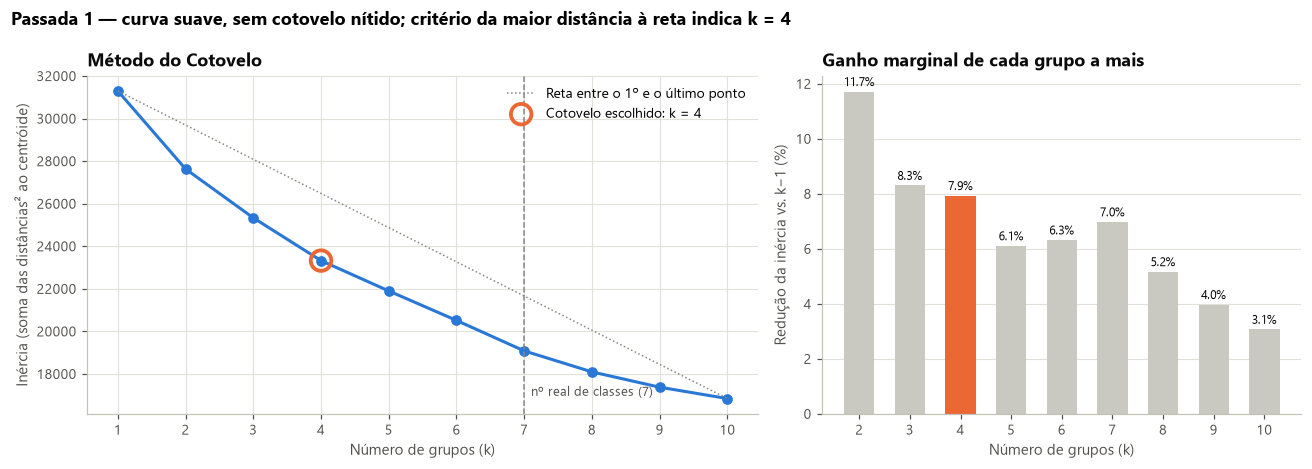

In [4]:
K.fig_cotovelo(curva, k_livre);

In [5]:
estab = K.estabilidade_cotovelo(Xs)
estab

,semente,k_cotovelo_1a10,k_cotovelo_2a10
0,0,4,6
1,7,4,6
2,42,4,7
3,123,4,6
4,2026,4,6


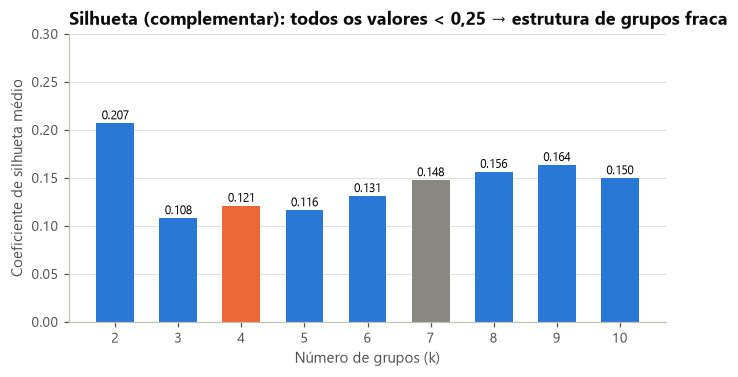

In [6]:
K.fig_silhueta(curva, k_livre);

**Leitura do cotovelo**

* A curva é **suave**, sem um "cotovelo" nítido — sinal de que os dados **não têm grupos bem separados**.
* O critério da maior distância à reta indica **k = 4** em todas as 5 sementes testadas. Os ganhos marginais confirmam: 11,7% → 8,3% → **7,9%** e depois
  caem para ~6% a partir de k = 5.
* Se tirarmos o k = 1 da curva, o critério oscila entre 6 e 7 conforme a semente — mais uma evidência de que não há um k "natural" forte.
* A **silhueta** (métrica complementar) fica abaixo de 0,25 para todo k: os grupos se sobrepõem muito.

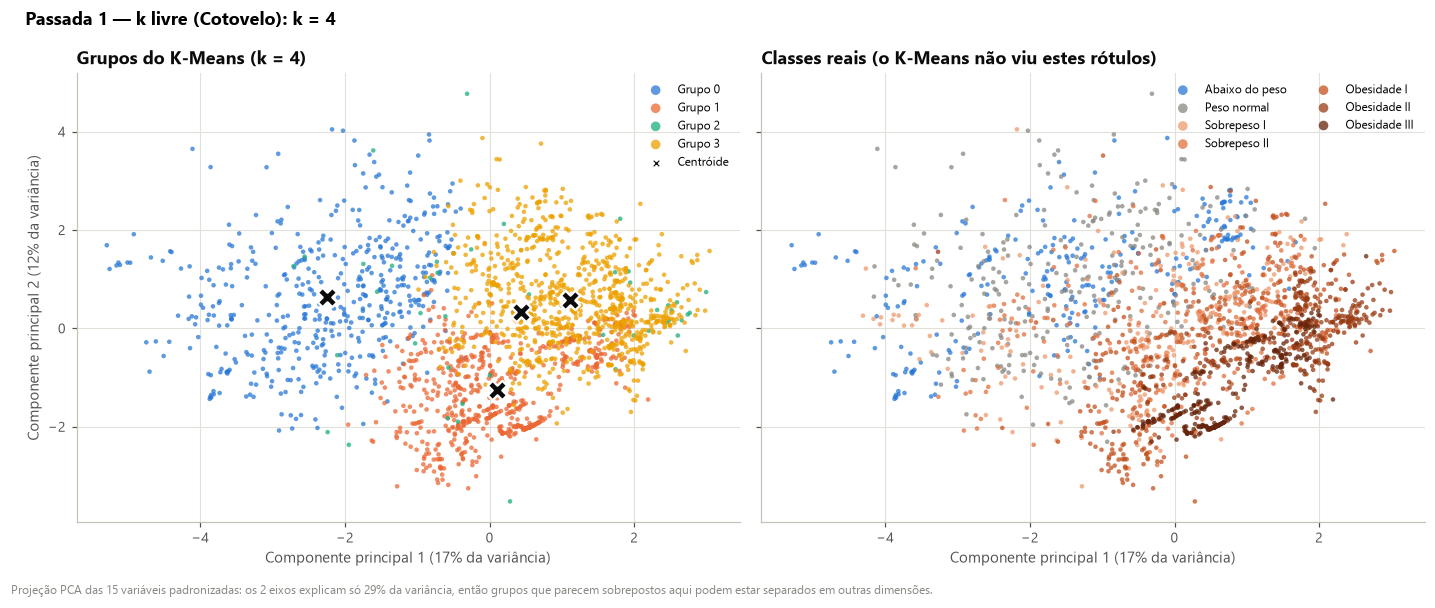

In [7]:
km_livre = K.ajustar(Xs, k_livre)
coords, pca = K.projecao_pca(Xs)
K.fig_clusters_pca(coords, km_livre.labels_, y, pca, f"Passada 1 — k livre (Cotovelo): k = {k_livre}",
                   pca.transform(km_livre.cluster_centers_));

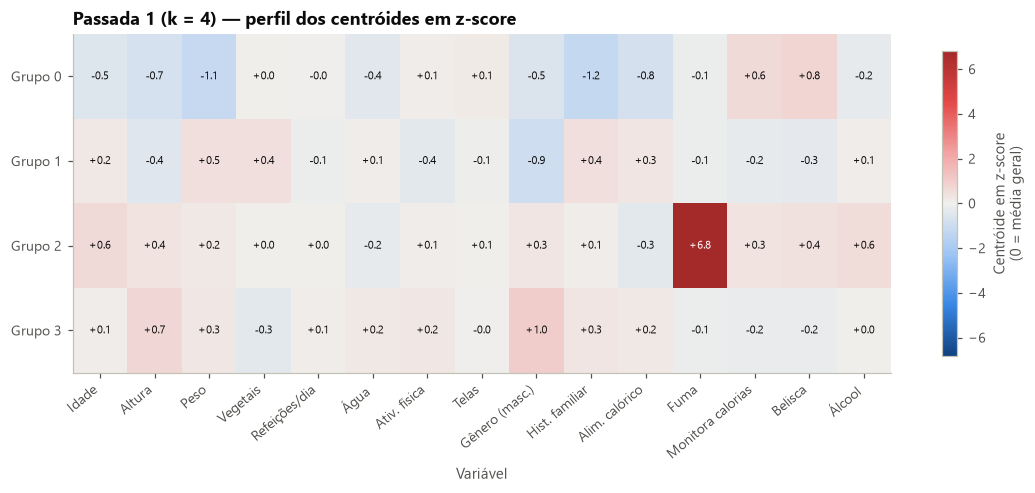

In [8]:
K.fig_perfil_centroides(km_livre, list(X.columns), f"Passada 1 (k = {k_livre}) — perfil dos centróides em z-score");

In [9]:
K.centroides_originais(km_livre, prep["scaler"], list(X.columns)).round(2)

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,Gender,family_history_with_overweight,FAVC,SMOKE,SCC,CAEC,CALC
cluster,,,,,,,,,,,,,,,
0,21.120,1.640,57.270,2.430,2.690,1.740,1.090,0.740,0.230,0.360,0.640,-0.000,0.170,1.510,0.600
1,25.680,1.660,99.040,2.680,2.610,2.070,0.680,0.620,0.040,0.990,0.990,-0.000,0.000,1.000,0.780
2,28.310,1.740,91.210,2.450,2.730,1.840,1.070,0.700,0.660,0.860,0.770,1.000,0.110,1.320,1.020
3,24.910,1.770,93.460,2.240,2.780,2.120,1.210,0.670,0.990,0.950,0.940,-0.000,0.010,1.050,0.740


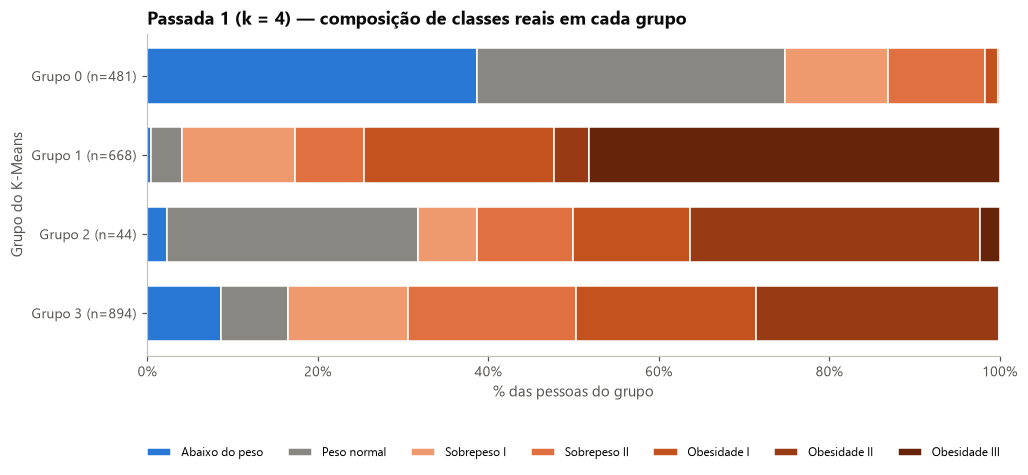

In [10]:
K.fig_composicao(km_livre.labels_, y, f"Passada 1 (k = {k_livre}) — composição de classes reais em cada grupo");

**Quem são os 4 grupos da Passada 1** (lendo os centróides):

| Grupo | Perfil | Classe majoritária |
|---|---|---|
| 0 | Jovens (21 anos), leves (57 kg), **sem** histórico familiar, beliscam mais | Abaixo do peso / Peso normal |
| 1 | **Mulheres** (96%), pesadas (99 kg), 99% com histórico familiar | Obesidade III (322 das 324) |
| 2 | **Fumantes** (100%) — só 44 pessoas | Obesidade II (fraco) |
| 3 | **Homens** (99%), altos, pesados (93 kg) | Obesidade II |

O K-Means separou primeiro por **gênero + peso**, não pelos 7 níveis de obesidade. E dedicou um grupo inteiro a uma característica rara (fumar),
que vira um valor z ≈ +6,8 após a padronização.

## 3. Passada 2 — k fixo = 7 (número real de classes)

k = 7 | inércia = 19,087 | silhueta = 0.148


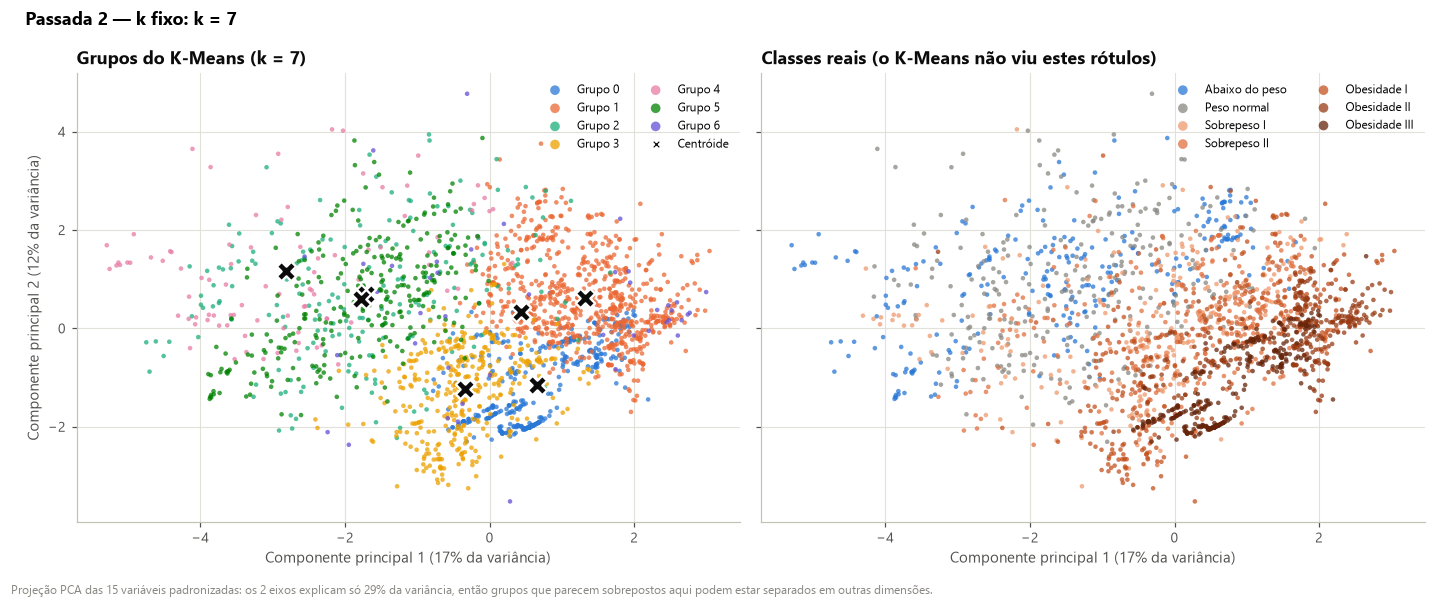

In [11]:
k_fixo = len(np.unique(y))
km_fixo = K.ajustar(Xs, k_fixo)
print(f"k = {k_fixo} | inércia = {km_fixo.inertia_:,.0f} | silhueta = {silhouette_score(Xs, km_fixo.labels_):.3f}")
K.fig_clusters_pca(coords, km_fixo.labels_, y, pca, f"Passada 2 — k fixo: k = {k_fixo}", pca.transform(km_fixo.cluster_centers_));

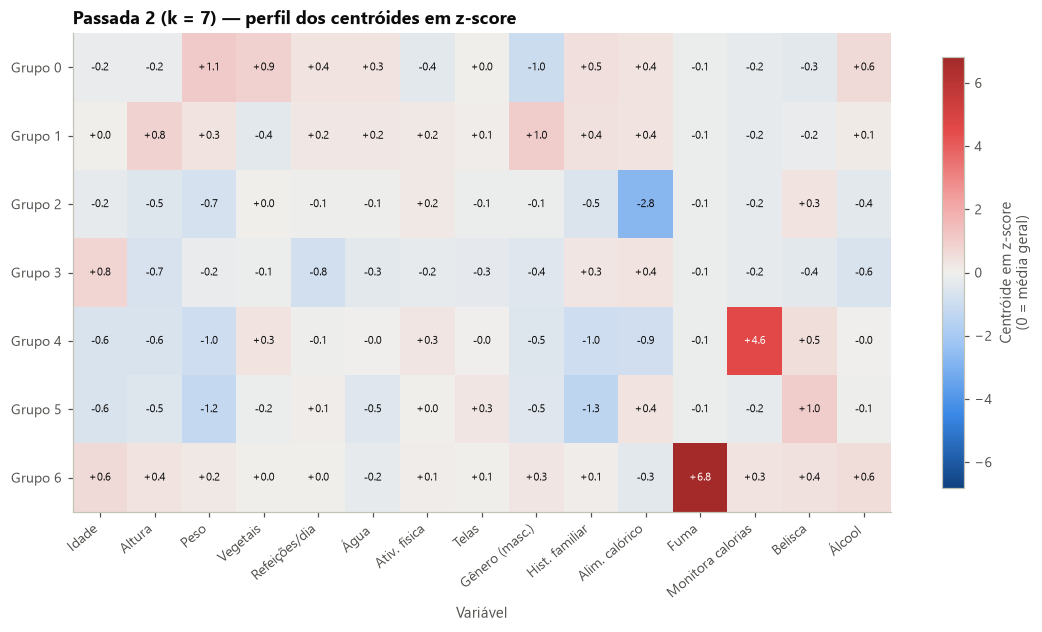

In [12]:
K.fig_perfil_centroides(km_fixo, list(X.columns), f"Passada 2 (k = {k_fixo}) — perfil dos centróides em z-score");

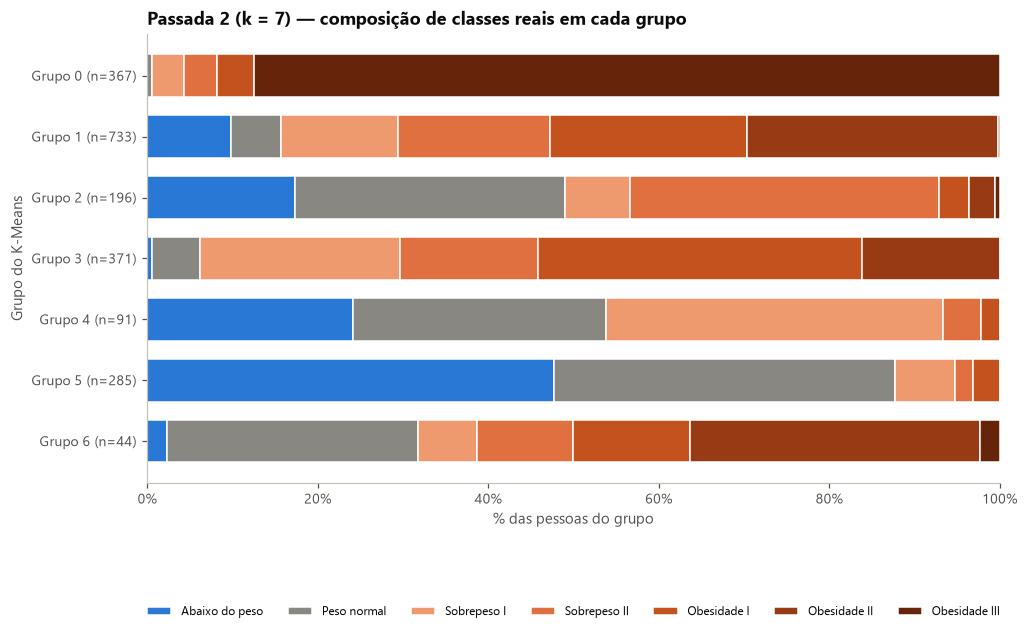

In [13]:
K.fig_composicao(km_fixo.labels_, y, f"Passada 2 (k = {k_fixo}) — composição de classes reais em cada grupo");

Com 7 grupos aparecem perfis mais finos, mas **dois grupos são "gastos" com atributos raros**: o Grupo 6 reúne os **44 fumantes** (z = +6,8) e o Grupo 4 quem
**monitora calorias** (z = +4,6). O Grupo 0 é quase puro (321 das 367 pessoas são Obesidade III) — consequência da homogeneidade artificial dessa classe.

## 4. Métricas: mapeamento, contingência, matriz de confusão

Regra: cada grupo recebe o rótulo da **classe real majoritária** dentro dele. Depois comparamos esse "rótulo previsto" com a classe real.
As métricas são calculadas **diretamente da matriz** (função `metricas_da_matriz`) e conferidas com o scikit-learn.

* **Acurácia** = soma da diagonal / total.
* **Precisão (classe X)** = acertos de X / total da **coluna** X → "das pessoas que o agrupamento chamou de X, quantas são X?"
* **Recall (classe X)** = acertos de X / total da **linha** X → "das pessoas que são X, quantas caíram em um grupo de X?"
* Se nenhum grupo foi mapeado para X, a precisão é **0/0 = indefinida** (mostrada como "—"; vale 0 na média macro).

In [14]:
res = {}
for nome, km_ in [("livre", km_livre), ("fixo", km_fixo)]:
    res[nome] = M.avaliar_passada(km_.labels_, y)
    print(f"[{nome}] k={res[nome]['k']} | mapeamento: {res[nome]['mapa']} | conferido com sklearn: {res[nome]['conferido_sklearn']}")

[livre] k=4 | mapeamento: {0: 'Abaixo do peso', 1: 'Obesidade III', 2: 'Obesidade II', 3: 'Obesidade II'} | conferido com sklearn: True
[fixo] k=7 | mapeamento: {0: 'Obesidade III', 1: 'Obesidade II', 2: 'Sobrepeso II', 3: 'Obesidade I', 4: 'Sobrepeso I', 5: 'Abaixo do peso', 6: 'Obesidade II'} | conferido com sklearn: True


### Passada 1 (k = 4)
A tabela de contingência é **retangular (7 classes × 4 grupos)**. A matriz de confusão é 7 × 7, mas como só há 4 grupos, no máximo 4 classes podem ser previstas.

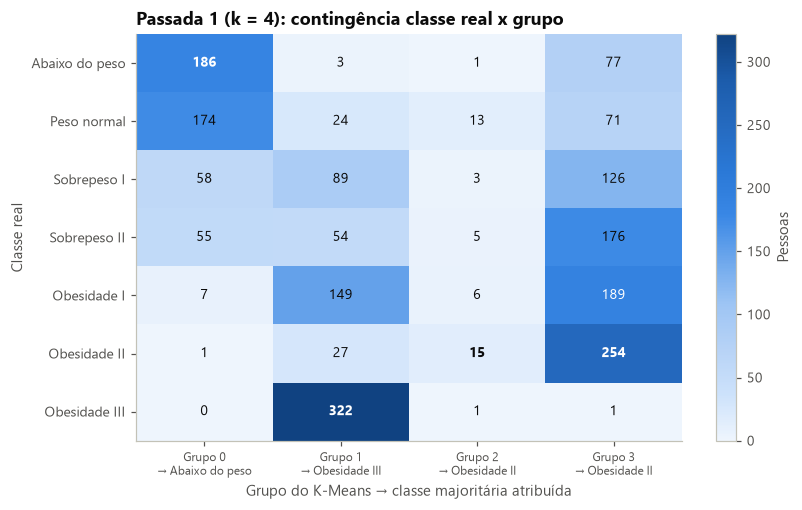

In [15]:
M.fig_contingencia(res["livre"]["contingencia"], res["livre"]["mapa"], "Passada 1 (k = 4): contingência classe real x grupo");

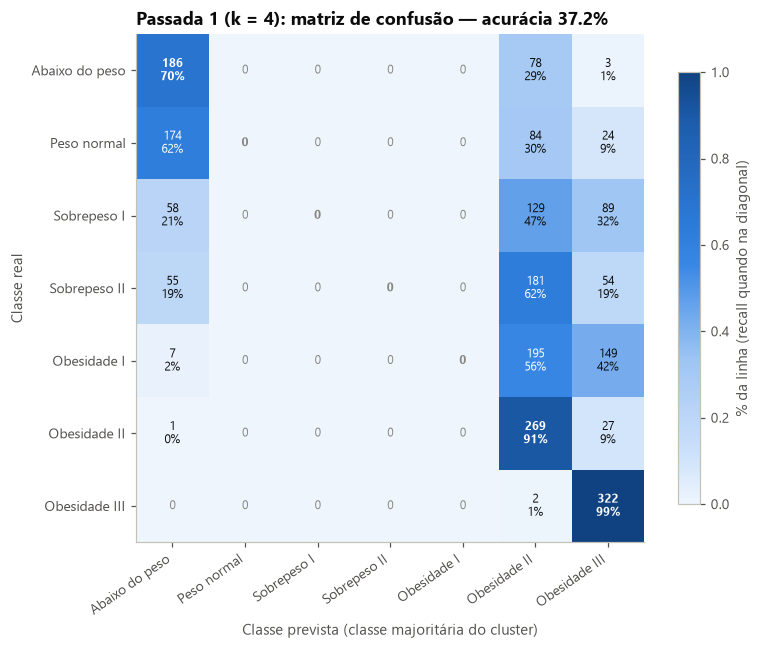

In [16]:
M.fig_matriz(res["livre"]["matriz"], f"Passada 1 (k = 4): matriz de confusão — acurácia {res['livre']['acuracia']:.1%}");

In [17]:
res["livre"]["por_classe"]

,classe,suporte_real,previstos,acertos,precisao,recall,f1
0,Abaixo do peso,267,481,186,0.387,0.697,0.497
1,Peso normal,282,0,0,NaN,0.000,NaN
2,Sobrepeso I,276,0,0,NaN,0.000,NaN
3,Sobrepeso II,290,0,0,NaN,0.000,NaN
4,Obesidade I,351,0,0,NaN,0.000,NaN
5,Obesidade II,297,938,269,0.287,0.906,0.436
6,Obesidade III,324,668,322,0.482,0.994,0.649


### Passada 2 (k = 7)

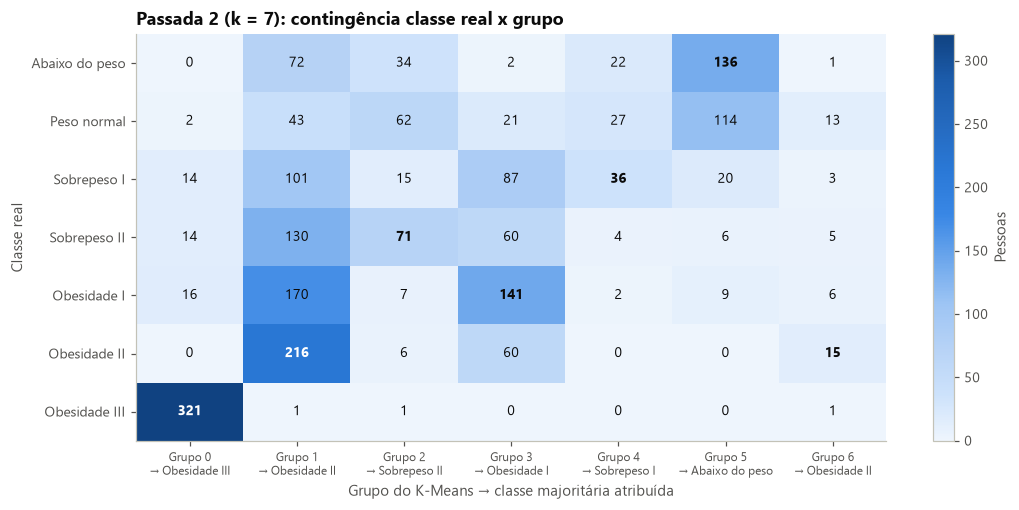

In [18]:
M.fig_contingencia(res["fixo"]["contingencia"], res["fixo"]["mapa"], "Passada 2 (k = 7): contingência classe real x grupo");

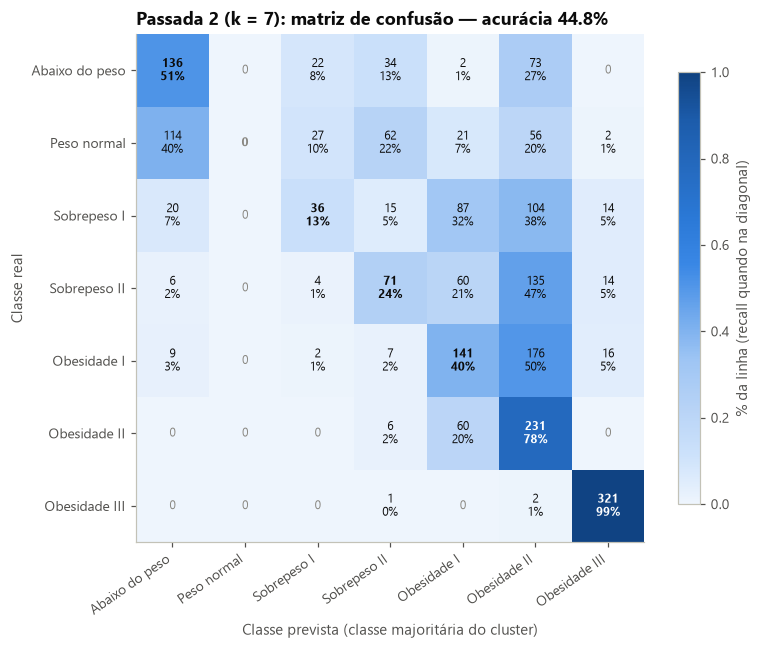

In [19]:
M.fig_matriz(res["fixo"]["matriz"], f"Passada 2 (k = 7): matriz de confusão — acurácia {res['fixo']['acuracia']:.1%}");

In [20]:
res["fixo"]["por_classe"]

,classe,suporte_real,previstos,acertos,precisao,recall,f1
0,Abaixo do peso,267,285,136,0.477,0.509,0.493
1,Peso normal,282,0,0,NaN,0.000,NaN
2,Sobrepeso I,276,91,36,0.396,0.130,0.196
3,Sobrepeso II,290,196,71,0.362,0.245,0.292
4,Obesidade I,351,371,141,0.380,0.402,0.391
5,Obesidade II,297,777,231,0.297,0.778,0.430
6,Obesidade III,324,367,321,0.875,0.991,0.929


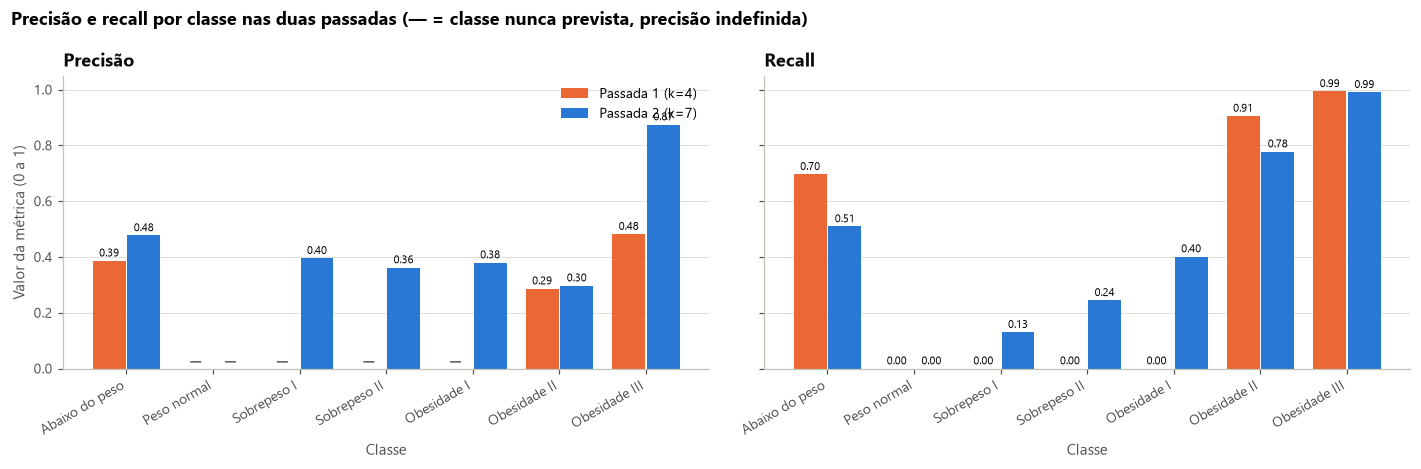

In [21]:
M.fig_comparacao(res["livre"], res["fixo"]);

In [22]:
pd.DataFrame([{"passada": n, "k": r["k"], "acuracia": r["acuracia"], "precisao_macro": r["precisao_macro"],
               "recall_macro": r["recall_macro"], "ARI": r["ari"], "NMI": r["nmi"],
               "silhueta": silhouette_score(Xs, (km_livre if n == "livre" else km_fixo).labels_),
               "classes_nunca_previstas": len(r["classes_nunca_previstas"])} for n, r in res.items()])

,passada,k,acuracia,precisao_macro,recall_macro,ARI,NMI,silhueta,classes_nunca_previstas
0,livre,4,0.372,0.165,0.371,0.183,0.271,0.121,4
1,fixo,7,0.448,0.398,0.436,0.243,0.338,0.148,1


**Leitura das matrizes**

* **Passada 1 (k = 4): acurácia 37,2%.** Quatro classes (Peso normal, Sobrepeso I, Sobrepeso II, Obesidade I) **nunca são previstas** → recall 0 e precisão indefinida.
  Dois grupos foram mapeados para Obesidade II. O que se salva: Obesidade III (recall 99%) e Abaixo do peso (recall 70%).
* **Passada 2 (k = 7): acurácia 44,8%** — 2,7× a linha de base de 16,8% (chutar sempre a classe mais comum). Seis classes passam a ser previstas.
  Obesidade III tem precisão 87% e recall 99%. **Peso normal continua nunca previsto**: as pessoas de peso normal se espalham pelos grupos e não são maioria em nenhum.
* Os erros se concentram em **classes vizinhas** (Sobrepeso I ↔ II ↔ Obesidade I; Abaixo do peso ↔ Normal) — a confusão segue a ordem do IMC.
* **ARI** (Adjusted Rand Index, 0 = acaso, 1 = idêntico) sobe de 0,18 para 0,24: a concordância é real, mas baixa.

## 5. Discussão crítica

### 5.1 Passada 1 (k livre) × Passada 2 (k fixo): qual gerou grupos mais coerentes?

Depende de "coerente com o quê":

* **Coerência com as classes reais:** a Passada 2 vence em tudo — acurácia (44,8% vs 37,2%), precisão macro (0,40 vs 0,17), recall macro (0,44 vs 0,37) e ARI (0,24 vs 0,18).
  Era esperado: com 7 grupos, há "vagas" para mais classes.
* **Coerência interna (estrutura dos dados):** nenhuma das duas é boa. A silhueta é baixa nas duas (0,12 vs 0,15) e a curva do cotovelo não tem um joelho claro.
  O cotovelo sugeriu 4 grupos — e esses 4 grupos fazem sentido **como perfis** (jovens leves, mulheres pesadas, homens pesados, fumantes), só que **não são as classes de obesidade**.
* Conclusão: os dados têm estrutura mais forte em **gênero + peso** do que nos 7 níveis. A Passada 2 só se aproxima das classes porque é "forçada" a ter 7 grupos,
  e ainda assim gasta 2 deles com fumantes e com quem monitora calorias.

### 5.2 A granularidade das classes faz sentido do ponto de vista dos dados?

Testamos reavaliar **os mesmos agrupamentos** contra versões mais grossas das classes:

In [23]:
pd.concat({"Passada 1 (k=4)": M.granularidade(km_livre.labels_, y),
           "Passada 2 (k=7)": M.granularidade(km_fixo.labels_, y)}).round(3)

agrupamento_de_classes  n_classes  acuracia_mapeada   ari   nmi  acuracia_chute_majoritario
Passada 1 (k=4) 0                                7 classes originais          7             0.372 0.183 0.271                       0.168
                1                       6 classes (Sobrepeso I + II)          6             0.395 0.185 0.285                       0.271
                2  4 classes OMS (Abaixo, Normal, Sobrepeso, Obes...          4             0.551 0.171 0.211                       0.466
                3    3 classes (Abaixo/Normal, Sobrepeso, Obesidade)          3             0.634 0.192 0.222                       0.466
Passada 2 (k=7) 0                                7 classes originais          7             0.448 0.243 0.338                       0.168
                1                       6 classes (Sobrepeso I + II)          6             0.468 0.235 0.344                       0.271
                2  4 classes OMS (Abaixo, Normal, Sobrepeso, Obes...          4             0.579 0.148 0.216                       0.466
                3    3 classes (Abaixo/Normal, Sobrepeso, Obesidade)          3             0.643 0.152 0.221                       0.466

* Juntar **Sobrepeso I + II** melhora a acurácia (37→40% e 45→47%) e mantém o ARI — os dados **não distinguem** esses dois níveis
  (sobreposição de IMC vista na EDA, e a OMS não faz essa divisão).
* Com as **4 classes da OMS**, a acurácia sobe para 55–58%, mas atenção: a linha de base também sobe (chutar "Obesidade" acerta 46,6%) e o ARI **não** melhora.
  Ou seja, juntar classes facilita a acurácia "de graça", sem que os grupos fiquem mais parecidos com as classes.
* **Sobrepeso I × Obesidade I** e **Abaixo do peso × Normal** também se misturam, porque a fronteira entre elas é um corte arbitrário numa variável contínua (IMC).

E o que define a classe?

In [24]:
K.sensibilidade_features(df, k=7).round(3)

,conjunto,n_variaveis,acuracia_mapeada,ari,silhueta
0,15 variáveis (usado),15,0.448,0.243,0.148
1,15 + MTRANS one-hot (20),20,0.407,0.213,0.136
2,Só hábitos e perfil (sem Altura/Peso),13,0.394,0.181,0.147
3,Só Altura e Peso,2,0.448,0.243,0.387


* **Só altura e peso** (2 variáveis) dão a **mesma acurácia** que as 15 (44,8%) — e uma silhueta **2,6× maior** (0,39). A classe é, de fato, IMC.
* **Só hábitos e perfil** (sem altura/peso) ainda acertam 39%: os hábitos carregam alguma informação, mas boa parte dela vem do artefato
  "Obesidade III = mulheres com hábitos idênticos".
* Incluir **MTRANS** por one-hot **piora** (40,7%) — confirma a decisão de deixá-la de fora.

### 5.3 Conclusões

1. A granularidade de 7 classes **não é sustentada pelos dados** como estrutura natural: as classes são cortes de uma variável contínua (IMC), e classes vizinhas — em especial
   **Sobrepeso I e II** — são indistinguíveis. Uma divisão em 4–5 níveis (como a da OMS) seria mais defensável.
2. O K-Means mede **semelhança global** entre pessoas; a classe depende de **2 variáveis**. Por isso o agrupamento revela outras estruturas (gênero, fumo, monitorar calorias)
   que são reais nos dados, mas não são a classe.
3. Parte do "acerto" (Obesidade III com 99% de recall) é **artefato do SMOTE**, que tornou algumas classes artificialmente homogêneas.
4. Lembrete: o K-Means nunca viu os rótulos. A "acurácia" mede **coincidência** entre grupos descobertos e classes conhecidas, não um acerto de previsão.